In [5]:
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp


import numpy as np
import pandas as pd


In [9]:
# Load model
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="face_landmarker.task"),
    running_mode=VisionRunningMode.IMAGE,
    num_faces=1,
    output_face_blendshapes=True
)

# Load image
image = mp.Image.create_from_file("data/test_image.png")

# Detect landmarks
with FaceLandmarker.create_from_options(options) as landmarker:
    result = landmarker.detect(image)

,_neutral,browDownLeft,browDownRight,browInnerUp,browOuterUpLeft,browOuterUpRight,cheekPuff,cheekSquintLeft,cheekSquintRight,eyeBlinkLeft,...,mouthShrugLower,mouthShrugUpper,mouthSmileLeft,mouthSmileRight,mouthStretchLeft,mouthStretchRight,mouthUpperUpLeft,mouthUpperUpRight,noseSneerLeft,noseSneerRight
0,6.141874e-07,0.002187,0.001594,0.334578,0.301427,0.321576,0.000191,1.272744e-07,1.400636e-07,0.407902,...,0.000059,0.000238,0.150016,0.197128,0.002774,0.002734,0.000043,0.000053,2.968233e-07,3.742238e-07


Number of landmarks: 478


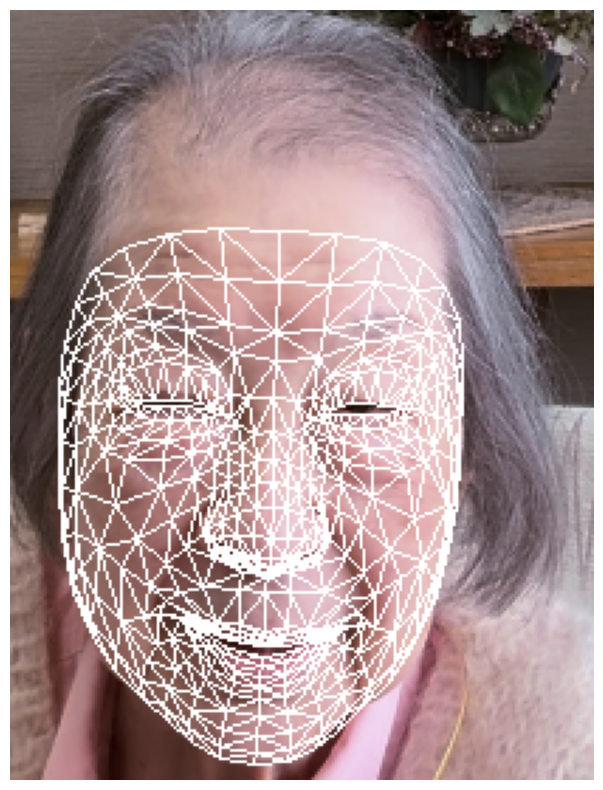

In [11]:
# Visualize
annotated_image = image.numpy_view().copy()
height, width, _ = annotated_image.shape

if result.face_landmarks:
    blendshapes = result.face_blendshapes[0]

    blendshape_features = {
        category.category_name: category.score
        for category in blendshapes
    }

    df = pd.DataFrame([blendshape_features])
    display(df)

    landmarks = result.face_landmarks[0]

    connections = (mp.tasks.vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION)

    for connection in connections:
        start = landmarks[connection.start]
        end = landmarks[connection.end]

        p1 = (int(start.x * width), int(start.y * height))
        p2 = (int(end.x * width), int(end.y * height))

        cv2.line(annotated_image, p1, p2, (0, 255, 0), 1)

    print(f"Number of landmarks: {len(landmarks)}")
    

plt.figure(figsize=(10, 10))
plt.imshow(annotated_image)
plt.axis("off")
plt.show()